Practical NO.03(A)  
Name - Sakshi Vijaykumar Muthiyan  
Roll No. -  
Title -  Implementation of Support Vector Machines (SVM) for classifying images of 
handwritten digits into their respective numerical classes (0 to 9).  

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
# loading built-in digits data from sklearn
digits = load_digits(n_class=10)
print("Total samples loaded:", len(digits.images))
print("Each image shape matrix:", digits.images[0].shape)

Total samples loaded: 1797
Each image shape matrix: (8, 8)


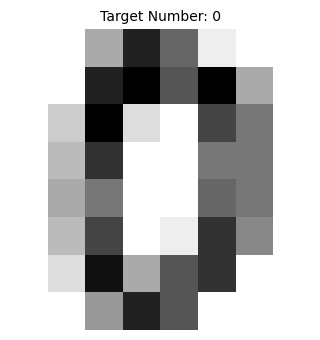

In [2]:
# checking the first image to verify the data
plt.figure(figsize=(5, 3.5))
# displaying gray scale image map
plt.imshow(digits.images[0], cmap=plt.cm.gray_r)
plt.title(f"Target Number: {digits.target[0]}", fontsize=10)
plt.axis('off')
plt.tight_layout()
plt.show()

In [3]:
# flattening 8x8 image grids into 64 array inputs
n_samples = len(digits.images)
X = digits.images.reshape((n_samples, -1))
y = digits.target
# 80-20 train test split split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# scaling values using standard scaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print("Training data dimensions shape:", X_train.shape)

Training data dimensions shape: (1437, 64)


In [4]:
# initializing svm classifier with rbf kernel
model = SVC(kernel='rbf', C=1.0)
model.fit(X_train, y_train)
# predicting values for testing set
y_pred = model.predict(X_test)
# printing standard accuracy and class performance stats
print("=== Classification Model Performance ===")
print("Accuracy Score Achieved:", round(accuracy_score(y_test, y_pred) * 100, 2), "%\n")
print(classification_report(y_test, y_pred))

=== Classification Model Performance ===
Accuracy Score Achieved: 98.06 %

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        33
           1       1.00      1.00      1.00        28
           2       1.00      1.00      1.00        33
           3       1.00      0.97      0.99        34
           4       0.96      1.00      0.98        46
           5       0.96      0.98      0.97        47
           6       0.97      1.00      0.99        35
           7       1.00      0.94      0.97        34
           8       0.97      0.97      0.97        30
           9       0.97      0.95      0.96        40

    accuracy                           0.98       360
   macro avg       0.98      0.98      0.98       360
weighted avg       0.98      0.98      0.98       360



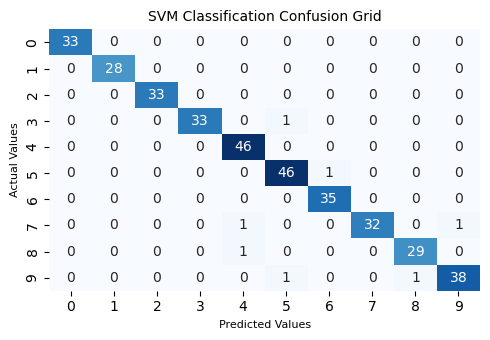

In [5]:
# calculating hit and miss confusion grid scores
cm = confusion_matrix(y_test, y_pred)
# keeping plot size small to save pages
plt.figure(figsize=(5, 3.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('SVM Classification Confusion Grid', fontsize=10)
plt.xlabel('Predicted Values', fontsize=8)
plt.ylabel('Actual Values', fontsize=8)
plt.tight_layout()
plt.show()